In [1]:
from dataframe_modify.add_positions import add_positions
from dataframe_modify.swap_perspective import swap_y
from dataframe_modify.swap_perspective import generalize_perspective
from dataframe_modify.grid_areas import add_grid_areas
from dataframe_modify.add_context import add_context
from get_data.get_data import get_merged_events
from get_data.get_data import get_sb360

MATCH_ID = 3836322

EVENTS_TO_ANALIZE = ['passes', 'carrys', 'ball_receipts', 'ball_recoverys', 'dribbles', 'blocks', 'clearances', 'duels',
'dispossesseds', 'errors', 'foul_committeds', 'foul_wons', 'half_ends', 'injury_stoppages', 'interceptions', 'miscontrols', 'shots']

frames = get_sb360(MATCH_ID)
events = get_merged_events(EVENTS_TO_ANALIZE, MATCH_ID)
start_team = events['possession_team'][0]

events = add_context(events, frames)
events = add_positions(events)
events = swap_y(events)
events = generalize_perspective(events, start_team)
events = add_grid_areas(events)

In [2]:
from sequences.get_sequences import get_sequences_by_possession

sequences = get_sequences_by_possession(events)
sequences[0]

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,context_locations,teammate_locations,actor_locations,start_x,start_y,end_x,end_y,start_area,end_area,area_code
0,91f5e387-8baa-47b0-82ba-b300bfc7a3bd,5,1,00:00:01.788,0,1,Pass,2,Lech Poznan,From Kick Off,...,[],[],[],61.0,39.9,44.0,40.6,G5,E4,G5E4
1,976e69a2-06f2-4693-8447-da5351af8239,6,1,00:00:02.937,0,2,Ball Receipt*,2,Lech Poznan,From Kick Off,...,"[[39.89566143614843, 26.75718526070478], [45.3...","[False, False, False, False, False, False, Tru...","[False, False, False, False, False, False, Fal...",44.0,40.6,,,E4,,E4
2,4aabd771-2bc6-4bfd-953a-1abe3b894626,7,1,00:00:02.937,0,2,Carry,2,Lech Poznan,From Kick Off,...,"[[80.10433856385157, 53.24281473929522], [74.6...","[False, False, False, False, False, False, Tru...","[False, False, False, False, False, False, Fal...",44.0,40.6,45.0,39.4,E4,E5,E4E5
3,5bb2c90b-c4e7-4ca4-b4f2-6d59d90651d3,8,1,00:00:03.698,0,3,Pass,2,Lech Poznan,From Kick Off,...,"[[82.42474475077002, 54.36488714005686], [76.4...","[False, False, False, False, False, True, True...","[False, False, False, False, False, False, Fal...",45.0,39.4,33.5,58.6,E5,D3,E5D3
4,60dcdfd7-becd-43d9-b577-a884dc83910c,9,1,00:00:05.181,0,5,Ball Receipt*,2,Lech Poznan,From Kick Off,...,"[[40.306550822439235, 17.551711562227773], [37...","[False, False, False, False, True, True, True,...","[False, False, False, False, False, False, Fal...",33.5,58.6,,,D3,,D3
5,13f58193-602d-4cb8-8e54-cfe6299117eb,10,1,00:00:05.181,0,5,Carry,2,Lech Poznan,From Kick Off,...,"[[79.69344917756077, 62.44828843777223], [82.4...","[False, False, False, False, True, True, True,...","[False, False, False, False, False, False, Fal...",33.5,58.6,33.5,58.6,D3,D3,D3D3
6,53751ba8-ff72-4bd2-bb90-99e55186fddc,11,1,00:00:06.327,0,6,Pass,2,Lech Poznan,From Kick Off,...,"[[78.21076348565485, 51.82178550530191], [74.4...","[False, False, True, False, False, True, False...","[False, False, False, False, False, False, Fal...",33.5,58.6,31.9,31.1,D3,D5,D3D5
7,ec5a8303-e619-43af-a9b3-b59361959f38,12,1,00:00:07.805,0,7,Ball Receipt*,2,Lech Poznan,From Kick Off,...,"[[42.75657034846516, 38.86986471215116], [45.5...","[False, False, False, False, True, True, False...","[False, False, False, False, False, False, Fal...",31.9,31.1,,,D5,,D5
8,3be60ad0-abce-446f-b42d-9c2cc3280c3d,13,1,00:00:07.805,0,7,Carry,2,Lech Poznan,From Kick Off,...,"[[77.24342965153484, 41.13013528784884], [74.4...","[False, False, False, False, True, True, False...","[False, False, False, False, False, False, Fal...",31.9,31.1,28.1,28.2,D5,C6,D5C6
9,499a6a9d-65a4-40b4-b5bb-50affebefceb,14,1,00:00:08.595,0,8,Pass,2,Lech Poznan,From Kick Off,...,"[[69.32088272399756, 45.685779881775325], [70....","[False, False, False, False, True, True, False...","[False, False, False, False, False, False, Fal...",28.1,28.2,28.8,9.5,C6,C8,C6C8


sequence 0
Team: Lech Poznan
1: Filip Bednarek (Pass) <00:17:07.152>
2: Pedro Miguel Braga Rebocho (Ball Receipt*) <00:17:09.881>
2: Pedro Miguel Braga Rebocho (Carry) <00:17:09.881>
2: Pedro Miguel Braga Rebocho (Pass) <00:17:11.721>
3: Michał Skóraś (Ball Receipt*) <00:17:13.814>


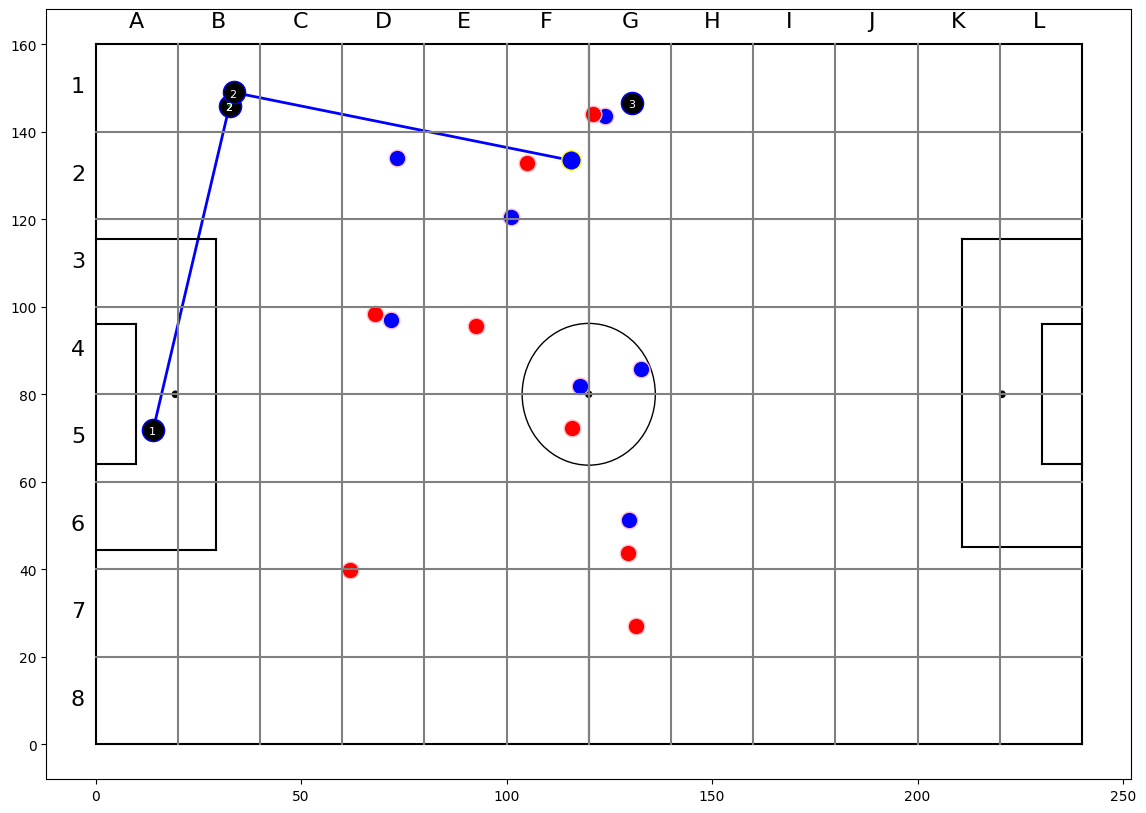

sequence 1
Team: Lech Poznan
1: Filip Bednarek (Pass) <00:28:29.571>
2: Mikael Ishak (Ball Receipt*) <00:28:33.067>
2: Mikael Ishak (Duel) <00:28:33.067>


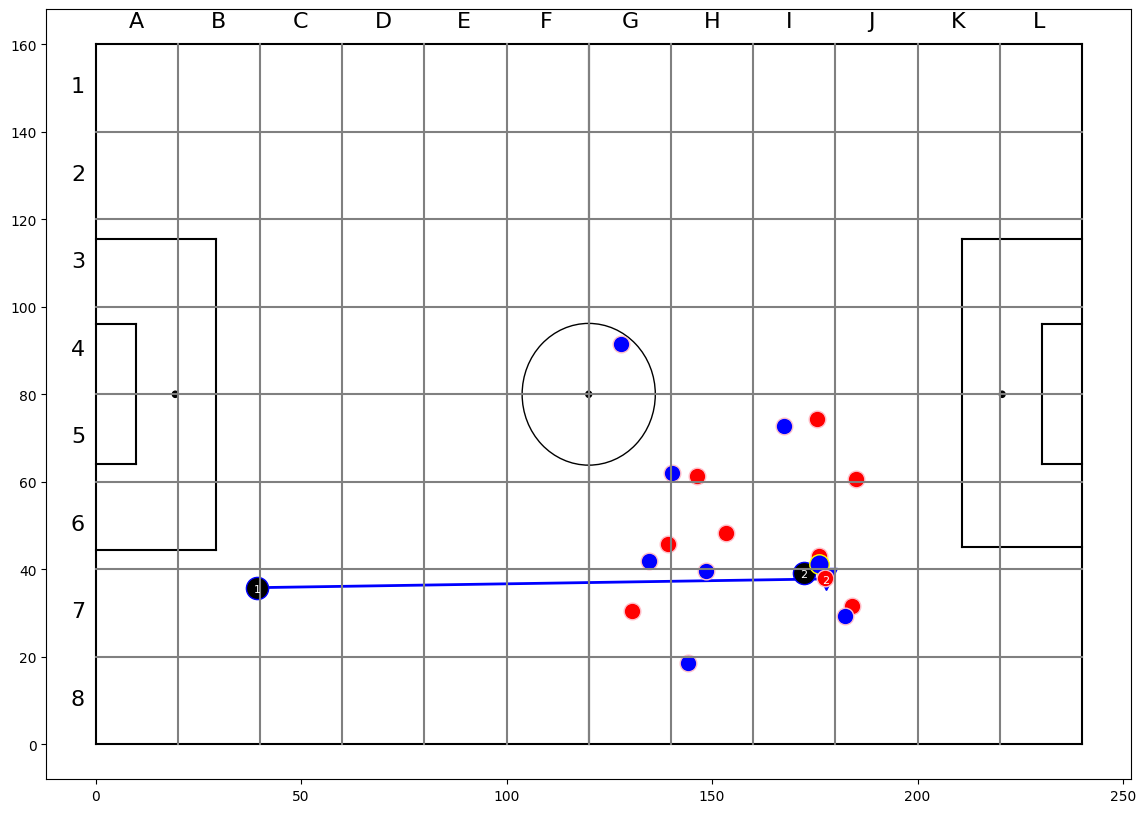

In [3]:
from draw.draw_sequences import draw_events_sequence
from sequences.find_fast_actions import find_fast_actions

fast_attact_lech_1 = find_fast_actions(sequences=sequences, team='Lech Poznan', start_team=start_team, half=1)

for i, s in enumerate(fast_attact_lech_1):
    print(f'sequence {i}')
    draw_events_sequence(s, start_team, 12, 8, scale=2)
    s.to_csv(f'sequence_{i}.csv')

In [12]:
from analysis.distance_from_line import distance_from_line

def metric_fast_sequence(df, frames, team, start_team, half):
    counterattack_pass = None
    if team == start_team and half == 1:
        team_half = {'A', 'B', 'C', 'D', 'E', 'F'}
    elif team != start_team and half == 2:
        team_half = {'A', 'B', 'C', 'D', 'E', 'F'}
    else:
        team_half = {'G', 'H', 'I', 'J', 'K', 'L'}
    for event_id, event_type, end_area in zip(df['id'].values, df['type'].values, df['end_area'].values):
        if event_type == 'Pass' and end_area[0] not in team_half:
            counterattack_pass = df.loc[df['id'] == event_id]
            break;
    if counterattack_pass is not None:
        context_locations = frames.loc[frames['id'] == counterattack_pass.id.values[0]]['location'].values
        teammate_locations = frames.loc[frames['id'] == counterattack_pass.id.values[0]]['teammate'].values
        enemy_locations = [location if not teammate else '' for location, teammate 
                            in zip(context_locations, teammate_locations)]
        enemy_locations = list(filter(lambda a: a != '', enemy_locations))
        counterattack_pass_path = [(counterattack_pass.start_x.values[0], counterattack_pass.start_y.values[0]),
        (counterattack_pass.end_x.values[0], counterattack_pass.end_y.values[0])]
        distances = [distance_from_line(counterattack_pass_path[0], counterattack_pass_path[1], location)
            for location in enemy_locations]
        distances2 = [1/distance_from_line(counterattack_pass_path[0], counterattack_pass_path[1], location)
            for location in enemy_locations]
        print(counterattack_pass_path)
        print(enemy_locations)
        print(distances)
        print(distances2)
metric_fast_sequence(fast_attact_lech_1[1], frames, 'Lech Poznan', start_team, 1)

[(19.7, 17.9), (88.9, 18.9)]
[[65.21940370878457, 45.474716503469594], [61.315764826590254, 56.49845927426737], [56.186278546351986, 64.67108767751486], [51.70632965164047, 45.22801697157153]]
[26.914111594775772, 37.99310859251873, 46.23900158014141, 26.86269306806408]
[0.037155229756649574, 0.026320562782191276, 0.021626764545657425, 0.03722634947531965]


In [5]:
fast_attact_lech_1[0]

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,context_locations,teammate_locations,actor_locations,start_x,start_y,end_x,end_y,start_area,end_area,area_code
311,5582715b-20ba-4bef-92fa-f13182896cdb,369,1,00:17:07.152,17,7,Pass,18,Lech Poznan,From Goal Kick,...,[],[],[],7.0,35.9,16.3,73.0,A5,B1,A5B1
312,57592e7a-f49f-4f8a-b77b-05a4a5ebd595,370,1,00:17:09.881,17,9,Ball Receipt*,18,Lech Poznan,From Goal Kick,...,"[[79.18406366388086, 11.798846316618068], [87....","[False, False, True, False, True, True, True]","[False, False, False, False, False, False, True]",16.3,73.0,,,B1,,B1
313,c4b89c2a-7513-4cd0-8f8a-0f9222308ca3,371,1,00:17:09.881,17,9,Carry,18,Lech Poznan,From Goal Kick,...,"[[40.81593633611914, 68.20115368338193], [32.8...","[False, False, True, False, True, True, True]","[False, False, False, False, False, False, True]",16.3,73.0,16.8,74.5,B1,B1,B1B1
314,3fcbf9f4-0a0d-44d0-9494-164ede6ac7e6,372,1,00:17:11.721,17,11,Pass,18,Lech Poznan,From Goal Kick,...,"[[22.238721422625375, 13.978646593122306], [29...","[True, False, True, True, False, False, True, ...","[False, False, False, False, False, False, Fal...",16.8,74.5,58.0,66.7,B1,F2,B1F2
315,cc3e25ea-1c17-4346-9bd0-580776b9ea4d,373,1,00:17:13.814,17,13,Ball Receipt*,18,Lech Poznan,From Goal Kick,...,"[[66.33204566281452, 42.90687297734646], [61.9...","[True, True, False, True, False, True, False, ...","[False, False, False, False, False, True, Fals...",65.3,73.3,,,G1,,G1


sequence 0
Team: Jagiellonia Białystok
1: Zlatan Alomerović (Pass) <00:15:56.477>
2: Marc Gual Huguet (Ball Receipt*) <00:16:01.837>
2: Marc Gual Huguet (Carry) <00:16:01.837>
2: Marc Gual Huguet (Pass) <00:16:03.313>
3: Tomáš Přikryl (Ball Receipt*) <00:16:04.345>
3: Tomáš Přikryl (Carry) <00:16:04.345>


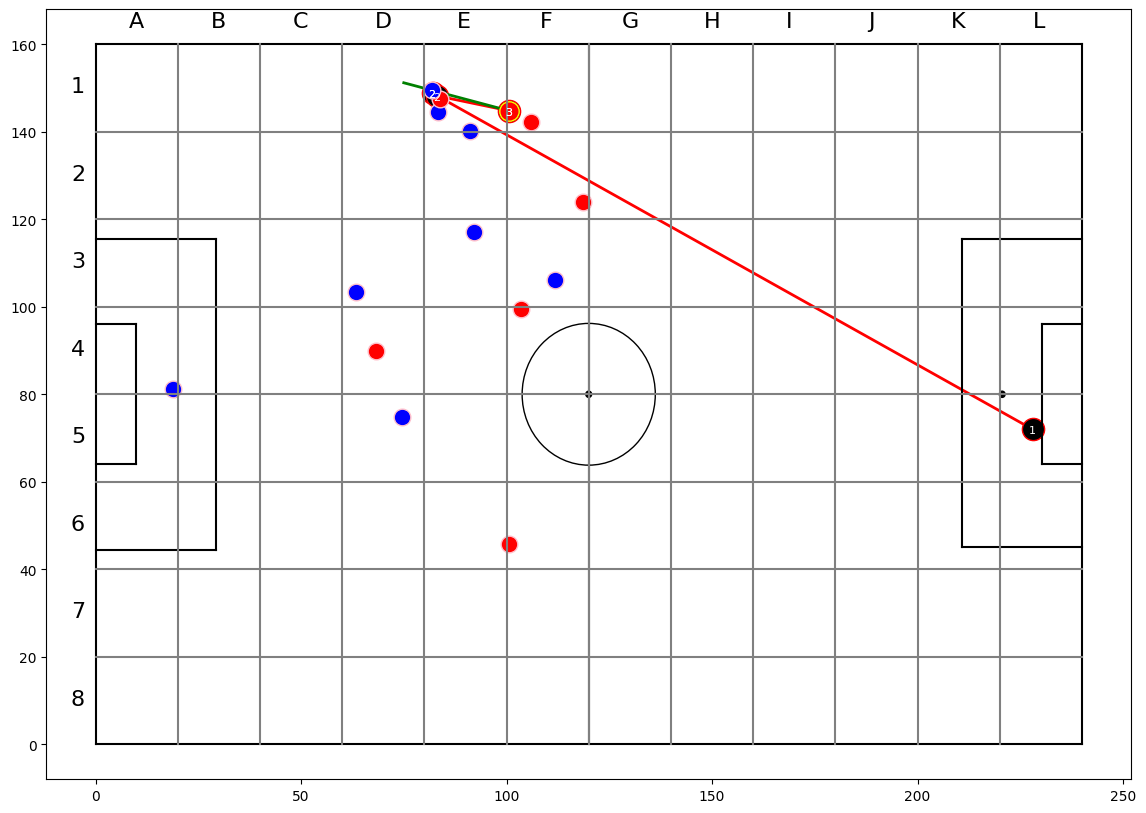

sequence 1
Team: Jagiellonia Białystok
1: Bogdan Ionuț Țîru (Pass) <00:22:37.859>
2: Tomáš Přikryl (Ball Receipt*) <00:22:39.557>
2: Tomáš Přikryl (Carry) <00:22:39.557>
2: Tomáš Přikryl (Pass) <00:22:40.685>
3: Bojan Nastić (Ball Receipt*) <00:22:41.418>
3: Bojan Nastić (Carry) <00:22:41.418>


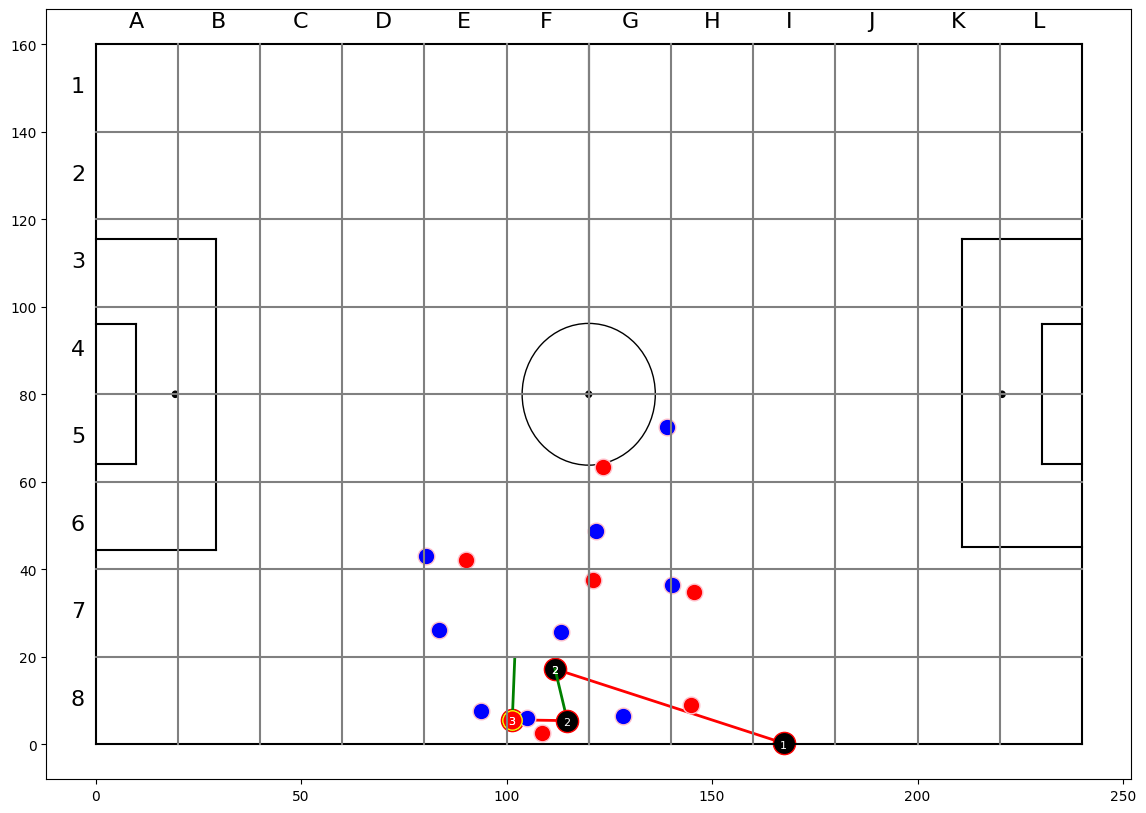

sequence 2
Team: Jagiellonia Białystok
1: Mateusz Skrzypczak (Pass) <00:25:20.744>
2: Israel Puerto Pineda (Ball Receipt*) <00:25:21.889>
2: Israel Puerto Pineda (Carry) <00:25:21.889>
2: Israel Puerto Pineda (Pass) <00:25:23.440>
3: Wojciech Łaski (Ball Receipt*) <00:25:24.437>


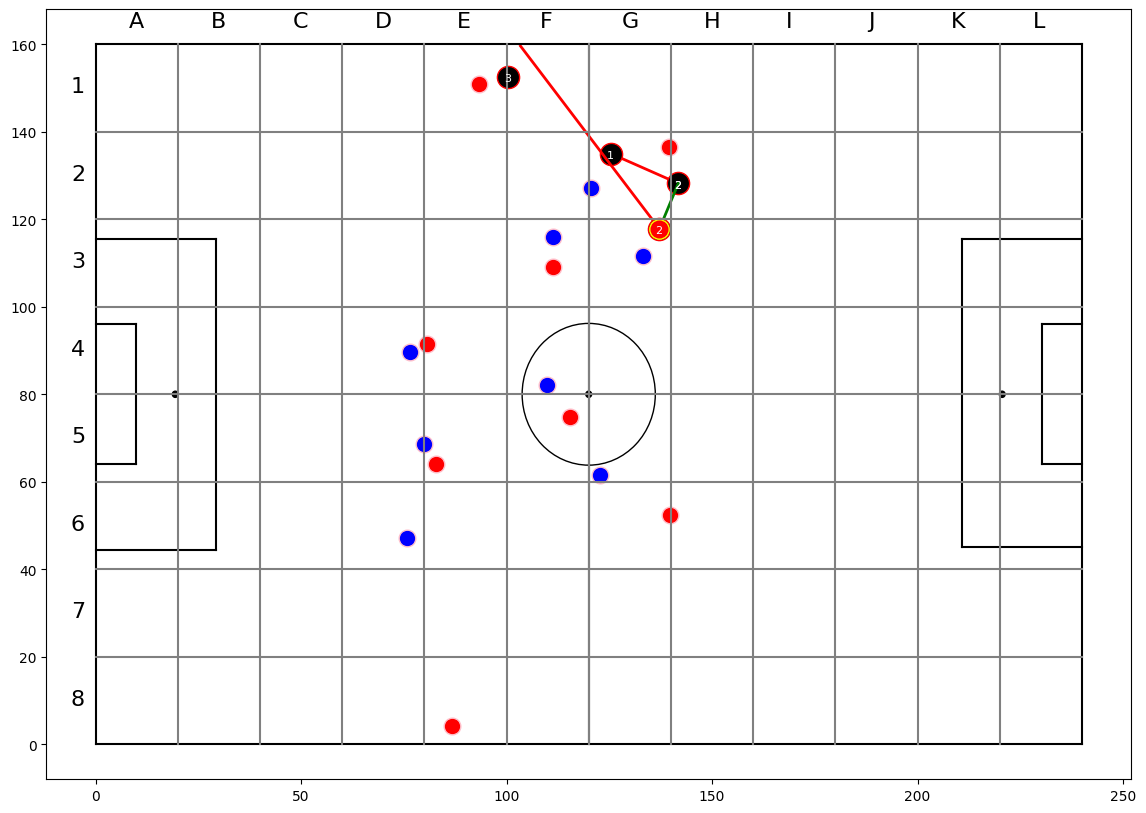

sequence 3
Team: Jagiellonia Białystok
1: Israel Puerto Pineda (Pass) <00:28:33.067>
2: Jesús Imaz Ballesté (Ball Receipt*) <00:28:34.509>
2: Jesús Imaz Ballesté (Carry) <00:28:34.509>
2: Jesús Imaz Ballesté (Pass) <00:28:35.109>
3: Marc Gual Huguet (Ball Receipt*) <00:28:35.319>
4: Ľubomír Šatka (Block) <00:28:35.319>
5: Tomáš Přikryl (Pass) <00:28:37.126>
6: Marc Gual Huguet (Ball Receipt*) <00:28:39.516>
6: Marc Gual Huguet (Pass) <00:28:39.516>
7: Jesús Imaz Ballesté (Ball Receipt*) <00:28:40.541>
7: Jesús Imaz Ballesté (Carry) <00:28:40.541>
7: Jesús Imaz Ballesté (Pass) <00:28:41.466>
8: Rui Filipe Cunha Correia (Ball Receipt*) <00:28:43.467>
8: Rui Filipe Cunha Correia (Carry) <00:28:43.467>
8: Rui Filipe Cunha Correia (Pass) <00:28:44.334>
9: Marc Gual Huguet (Ball Receipt*) <00:28:44.462>
10: Ľubomír Šatka (Block) <00:28:44.462>


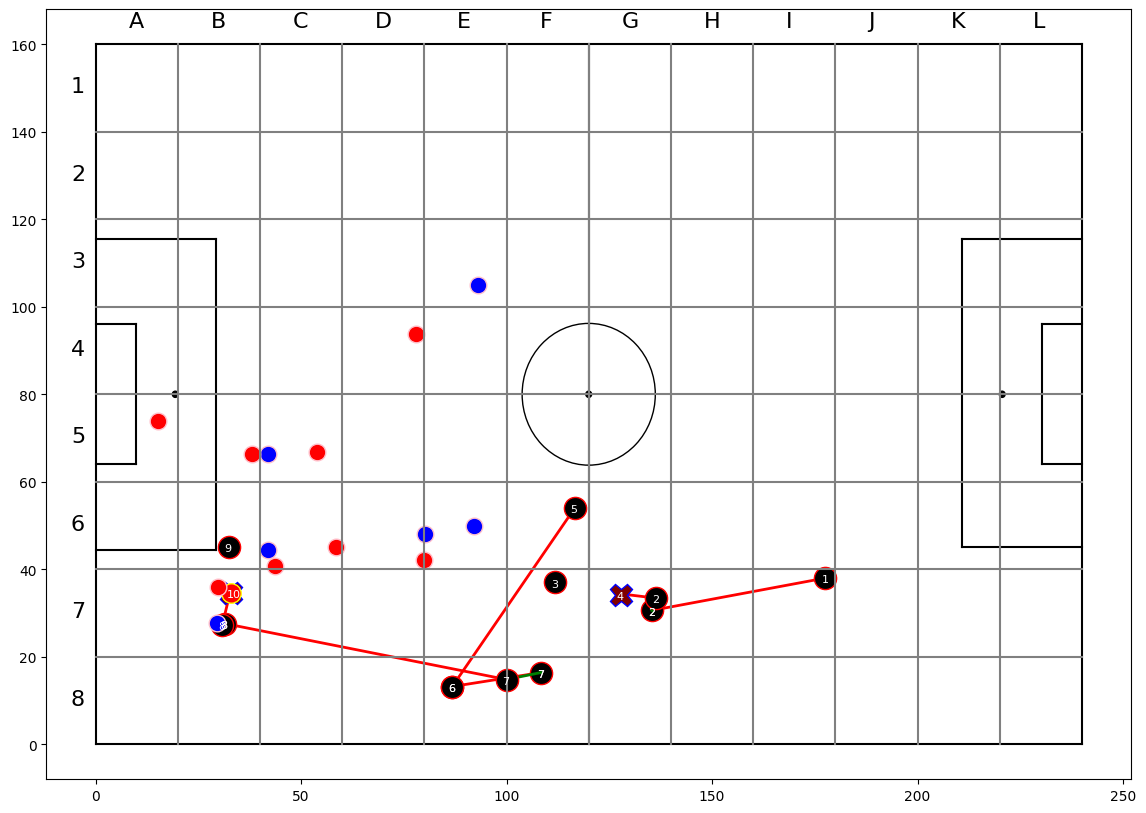

sequence 4
Team: Jagiellonia Białystok
1: Mateusz Skrzypczak (Ball Recovery) <00:31:15.753>
1: Mateusz Skrzypczak (Carry) <00:31:15.753>
1: Mateusz Skrzypczak (Pass) <00:31:16.684>
2: Zlatan Alomerović (Ball Receipt*) <00:31:18.685>
2: Zlatan Alomerović (Carry) <00:31:18.685>
2: Zlatan Alomerović (Pass) <00:31:20.425>
3: Tomáš Přikryl (Ball Receipt*) <00:31:23.236>
3: Tomáš Přikryl (Pass) <00:31:23.236>
4: Marc Gual Huguet (Ball Receipt*) <00:31:24.525>


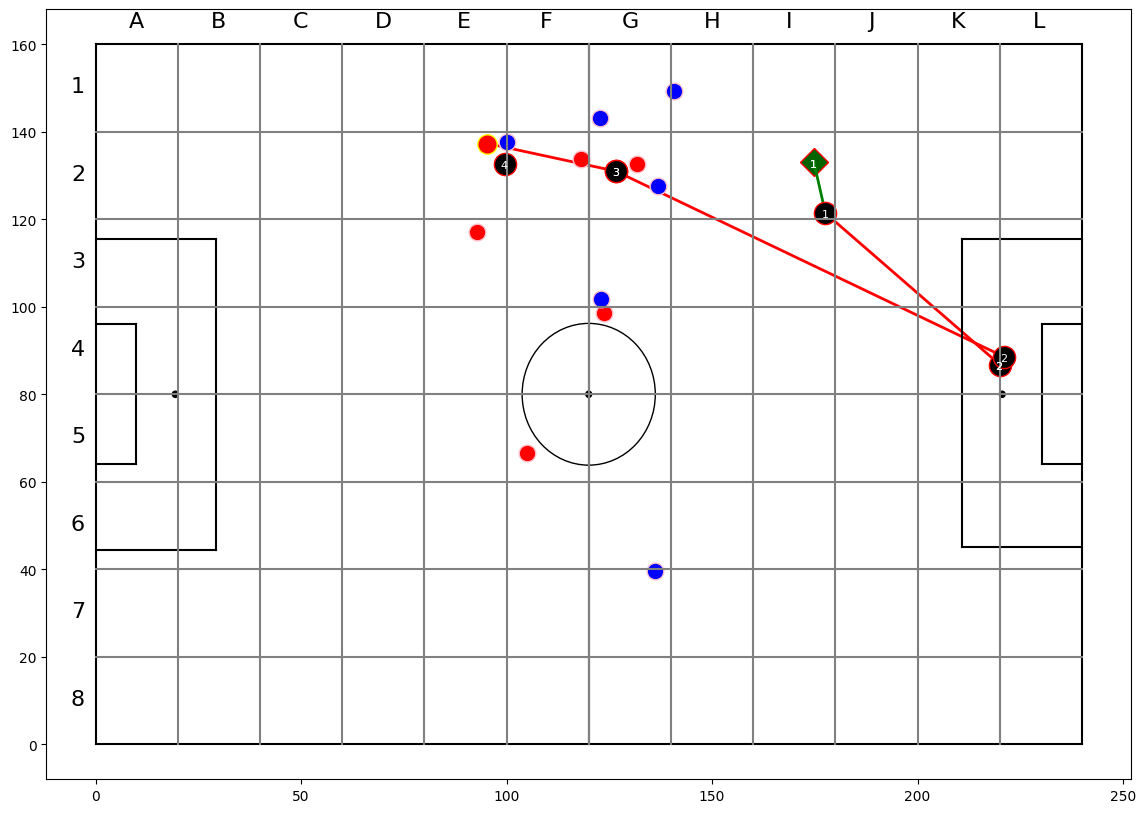

sequence 5
Team: Jagiellonia Białystok
1: Mateusz Skrzypczak (Pass) <00:39:52.097>
2: Tomáš Přikryl (Ball Receipt*) <00:39:52.934>
2: Tomáš Přikryl (Pass) <00:39:52.934>
3: Mateusz Skrzypczak (Ball Receipt*) <00:39:54.505>
3: Mateusz Skrzypczak (Pass) <00:39:54.505>
4: Rui Filipe Cunha Correia (Ball Receipt*) <00:39:55.982>
5: Jesper Karlström (Pass) <00:39:55.982>
6: Pedro Miguel Braga Rebocho (Ball Receipt*) <00:39:58.520>


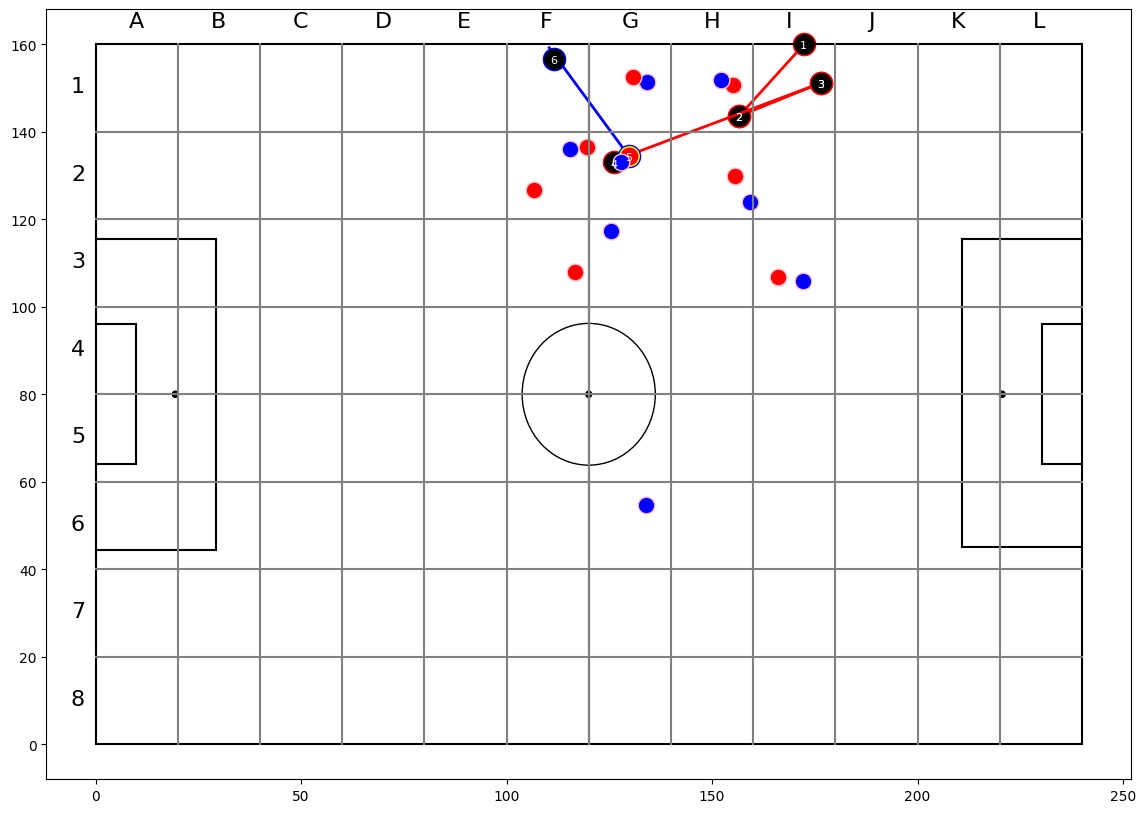

sequence 6
Team: Jagiellonia Białystok
1: Zlatan Alomerović (Pass) <00:42:13.723>
2: Rui Filipe Cunha Correia (Ball Receipt*) <00:42:15.091>
2: Rui Filipe Cunha Correia (Carry) <00:42:15.091>
2: Rui Filipe Cunha Correia (Pass) <00:42:19.078>
3: Marc Gual Huguet (Ball Receipt*) <00:42:20.372>
3: Marc Gual Huguet (Pass) <00:42:20.372>
4: Miłosz Matysik (Ball Receipt*) <00:42:21.652>
4: Miłosz Matysik (Pass) <00:42:21.652>
5: Jesús Imaz Ballesté (Ball Receipt*) <00:42:23.502>


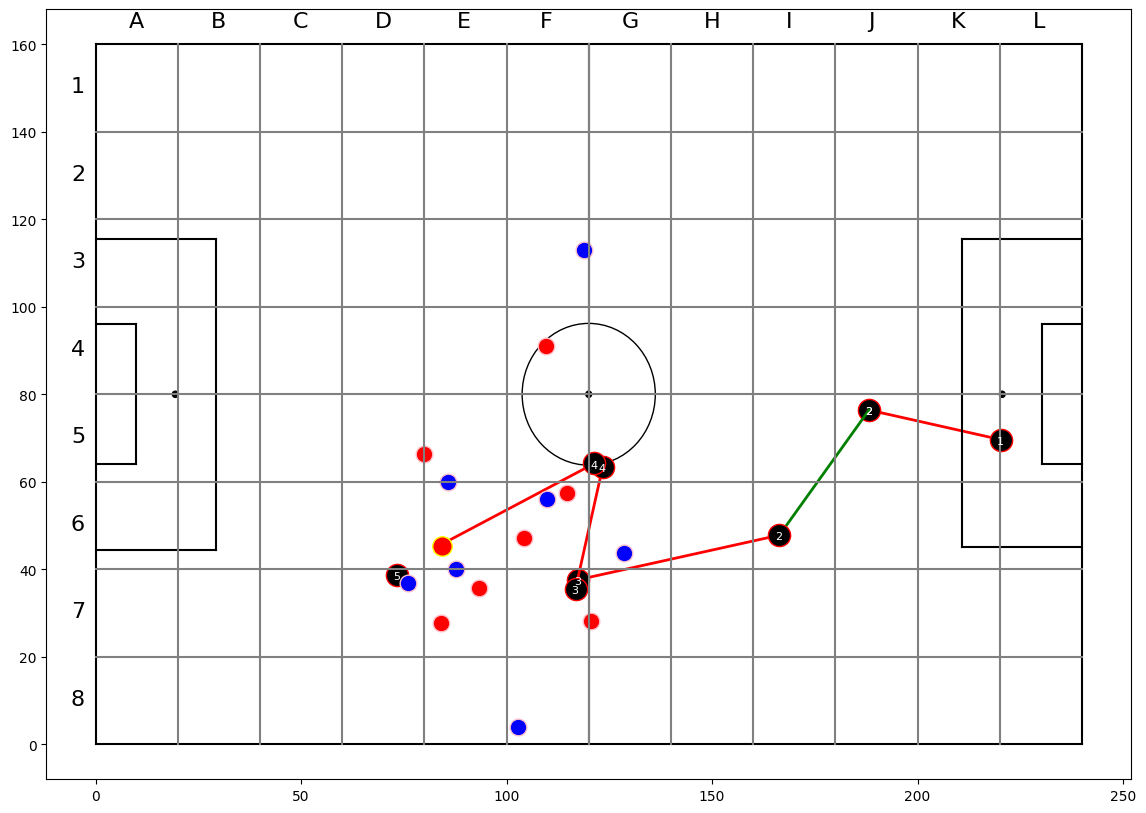

sequence 7
Team: Jagiellonia Białystok
1: Israel Puerto Pineda (Pass) <00:52:38.240>
2: Wojciech Łaski (Ball Receipt*) <00:52:40.047>
2: Wojciech Łaski (Pass) <00:52:40.064>
3: Tomáš Přikryl (Ball Receipt*) <00:52:41.602>
4: Jesper Karlström (Interception) <00:52:41.602>
4: Jesper Karlström (Carry) <00:52:41.602>
4: Jesper Karlström (Pass) <00:52:42.825>
5: João Pedro Reis Amaral (Ball Receipt*) <00:52:44.737>
6: Miłosz Matysik (Pass) <00:52:44.737>
7: Israel Puerto Pineda (Ball Receipt*) <00:52:46.676>
7: Israel Puerto Pineda (Pass) <00:52:46.676>
8: Mateusz Skrzypczak (Ball Receipt*) <00:52:47.514>
8: Mateusz Skrzypczak (Carry) <00:52:47.514>
8: Mateusz Skrzypczak (Pass) <00:52:49.404>
9: Wojciech Łaski (Ball Receipt*) <00:52:50.274>
9: Wojciech Łaski (Carry) <00:52:50.274>


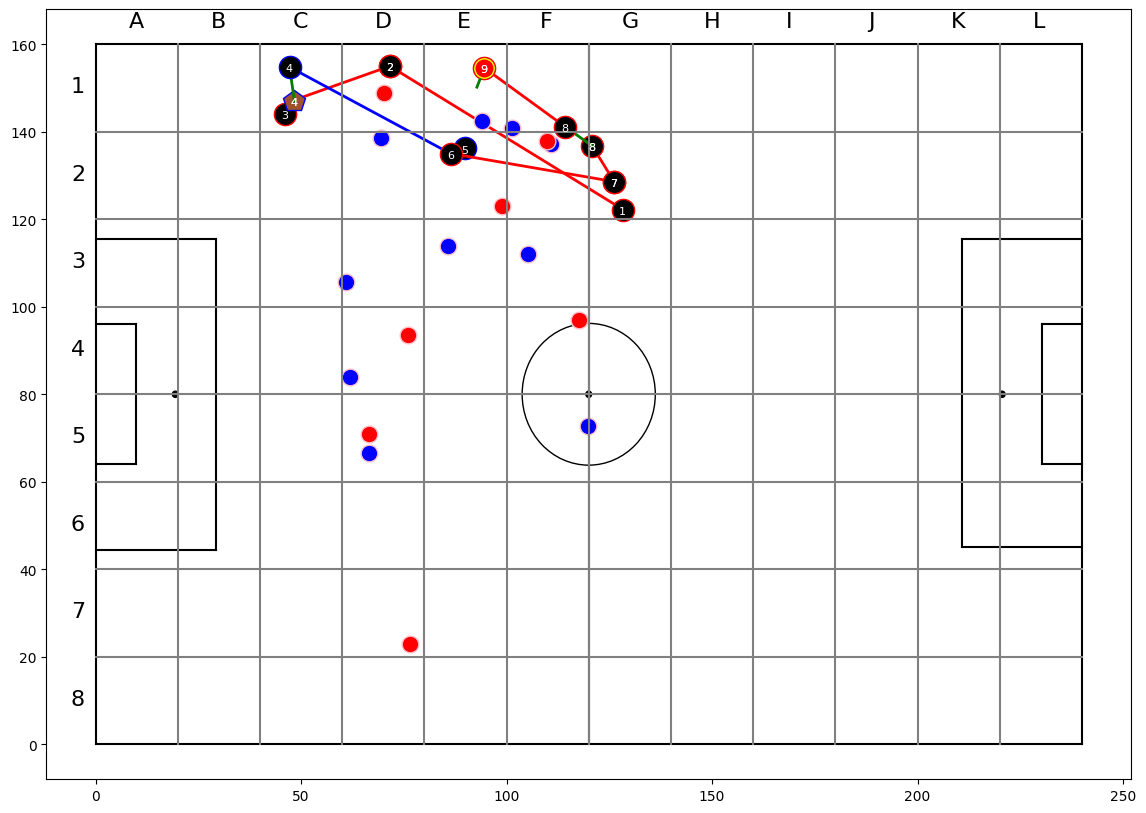

In [6]:
from draw.draw_sequences import draw_events_sequence
from sequences.find_fast_actions import find_fast_actions

fast_attact_jagiellonia_1 = find_fast_actions(sequences=sequences, team='Jagiellonia Białystok', start_team=start_team, half=1)

for i, s in enumerate(fast_attact_jagiellonia_1):
    print(f'sequence {i}')
    draw_events_sequence(s, start_team, 12, 8, scale=2)

sequence 0
Team: Lech Poznan
1: Radosław Murawski (Ball Recovery) <00:09:58.382>
1: Radosław Murawski (Carry) <00:09:58.382>
1: Radosław Murawski (Pass) <00:10:00.360>
2: Jesper Karlström (Ball Receipt*) <00:10:00.527>
2: Jesper Karlström (Carry) <00:10:00.527>
3: Marc Gual Huguet (Block) <00:10:00.527>
4: Jesper Karlström (Pass) <00:10:02.023>
5: João Pedro Reis Amaral (Ball Receipt*) <00:10:03.731>
5: João Pedro Reis Amaral (Carry) <00:10:03.731>
5: João Pedro Reis Amaral (Pass) <00:10:04.861>
6: Michał Skóraś (Ball Receipt*) <00:10:08.945>
7: Wojciech Łaski (Interception) <00:10:08.945>


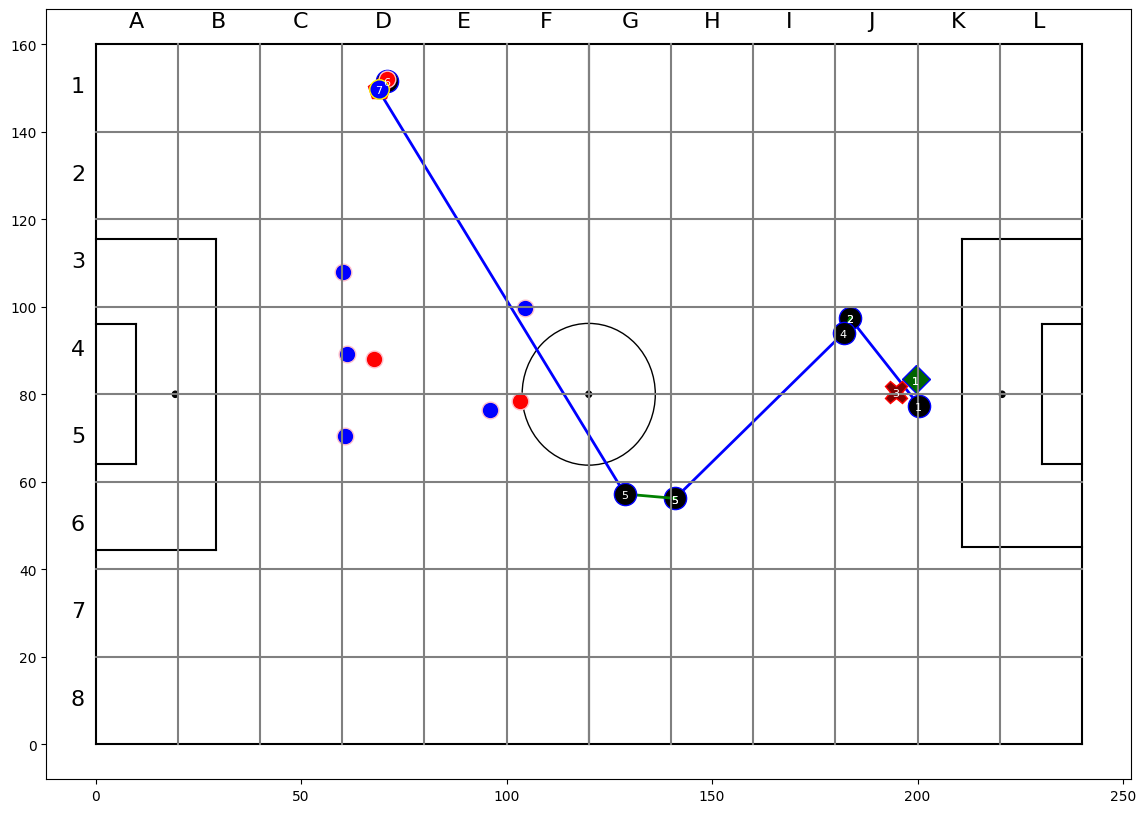

sequence 1
Team: Lech Poznan
1: Radosław Murawski (Ball Recovery) <00:35:24.888>
1: Radosław Murawski (Carry) <00:35:24.888>
1: Radosław Murawski (Dispossessed) <00:35:25.754>
2: Marc Gual Huguet (Duel) <00:35:25.754>
3: Rui Filipe Cunha Correia (Pass) <00:35:27.438>
4: Filip Szymczak (Ball Recovery) <00:35:28.440>
4: Filip Szymczak (Carry) <00:35:28.440>
4: Filip Szymczak (Pass) <00:35:29.302>
5: Joel Vieira Pereira (Ball Receipt*) <00:35:30.486>
5: Joel Vieira Pereira (Carry) <00:35:30.486>
5: Joel Vieira Pereira (Pass) <00:35:31.712>
6: Filip Szymczak (Ball Receipt*) <00:35:34.861>
6: Filip Szymczak (Carry) <00:35:34.861>


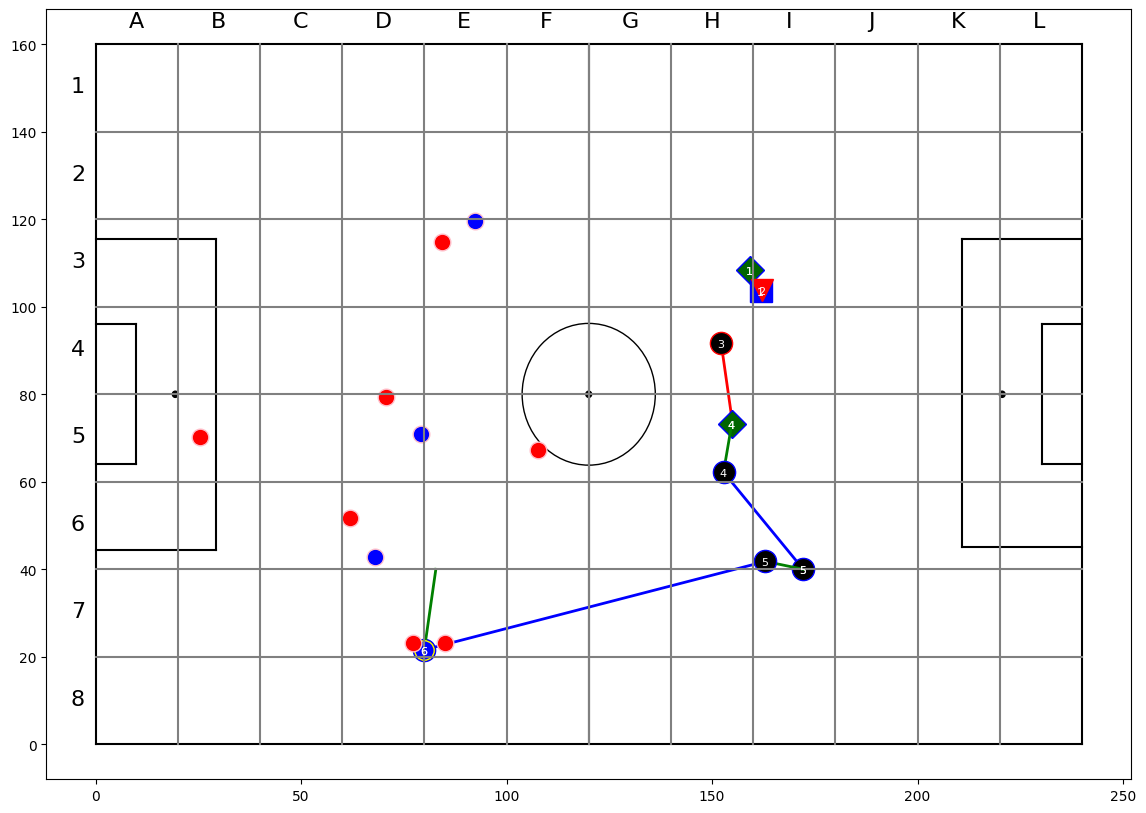

sequence 2
Team: Lech Poznan
1: Radosław Murawski (Duel) <00:35:58.344>
2: Jesper Karlström (Ball Recovery) <00:35:59.470>
2: Jesper Karlström (Carry) <00:35:59.470>
2: Jesper Karlström (Pass) <00:36:00.788>
3: Heorhii Tsitaishvili (Ball Receipt*) <00:36:03.804>
3: Heorhii Tsitaishvili (Carry) <00:36:03.804>
3: Heorhii Tsitaishvili (Dribble) <00:36:07.363>
4: Bojan Nastić (Duel) <00:36:07.363>


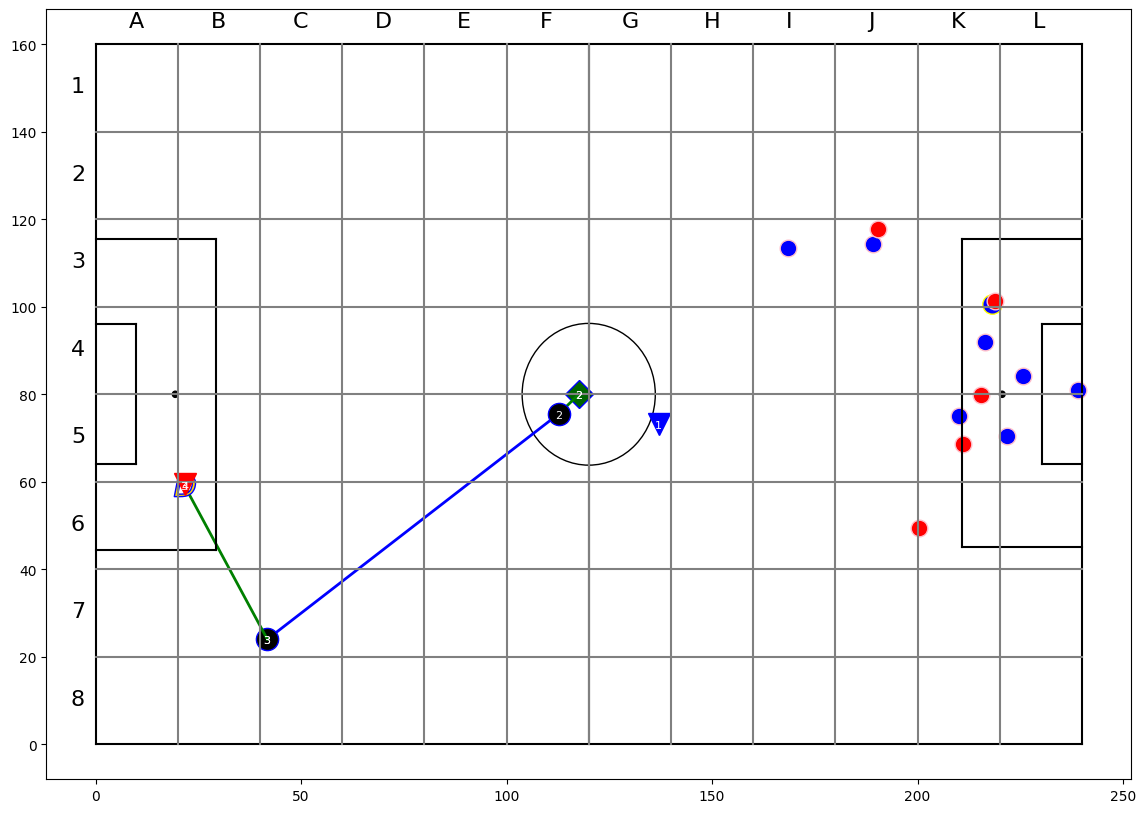

sequence 3
Team: Lech Poznan
1: Joel Vieira Pereira (Pass) <00:38:13.819>
2: Heorhii Tsitaishvili (Ball Receipt*) <00:38:15.429>
2: Heorhii Tsitaishvili (Carry) <00:38:15.429>
2: Heorhii Tsitaishvili (Pass) <00:38:15.761>
3: Joel Vieira Pereira (Ball Receipt*) <00:38:16.900>
3: Joel Vieira Pereira (Carry) <00:38:16.900>
3: Joel Vieira Pereira (Pass) <00:38:18.675>
4: Heorhii Tsitaishvili (Ball Receipt*) <00:38:19.175>


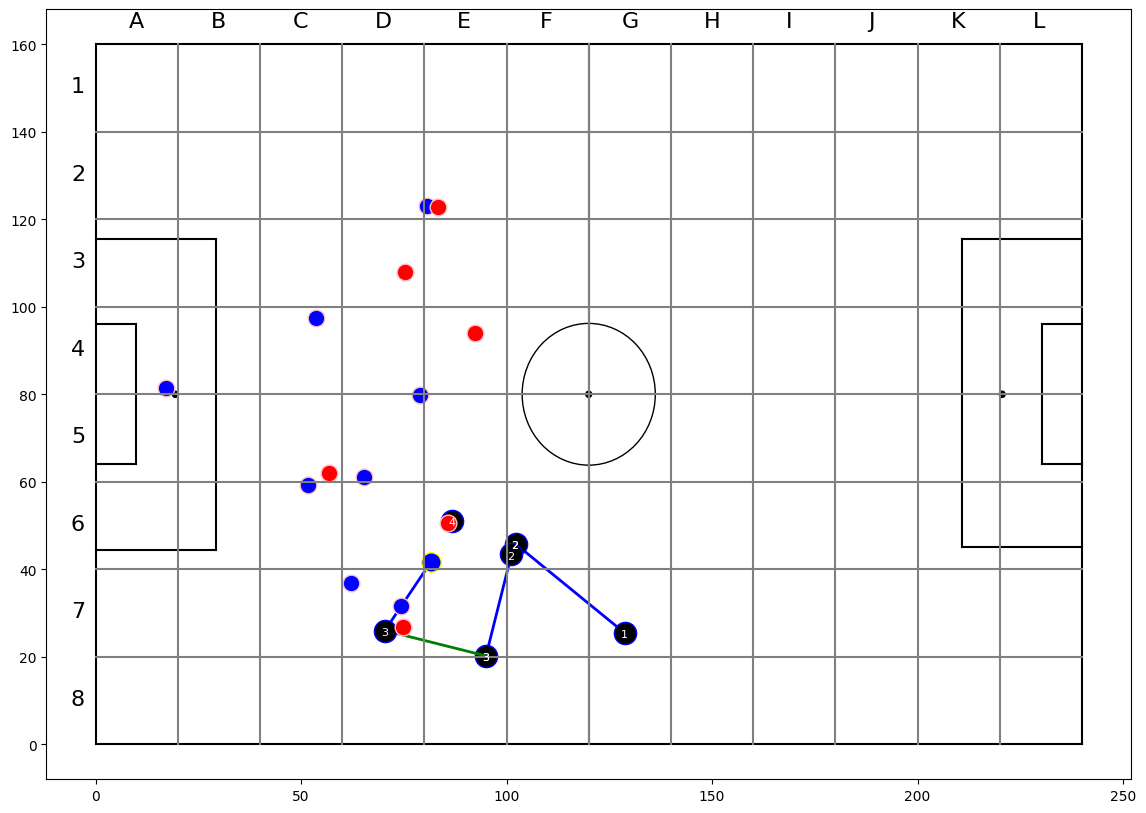

sequence 4
Team: Lech Poznan
1: Ľubomír Šatka (Pass) <00:44:05.137>
2: Adriel D''Avila Ba Loua (Ball Receipt*) <00:44:06.725>
2: Adriel D''Avila Ba Loua (Carry) <00:44:06.725>
2: Adriel D''Avila Ba Loua (Pass) <00:44:08.287>
3: Joel Vieira Pereira (Ball Receipt*) <00:44:10.548>
3: Joel Vieira Pereira (Carry) <00:44:10.548>
3: Joel Vieira Pereira (Pass) <00:44:12.513>
4: Filip Szymczak (Ball Receipt*) <00:44:13.839>
4: Filip Szymczak (Carry) <00:44:13.839>


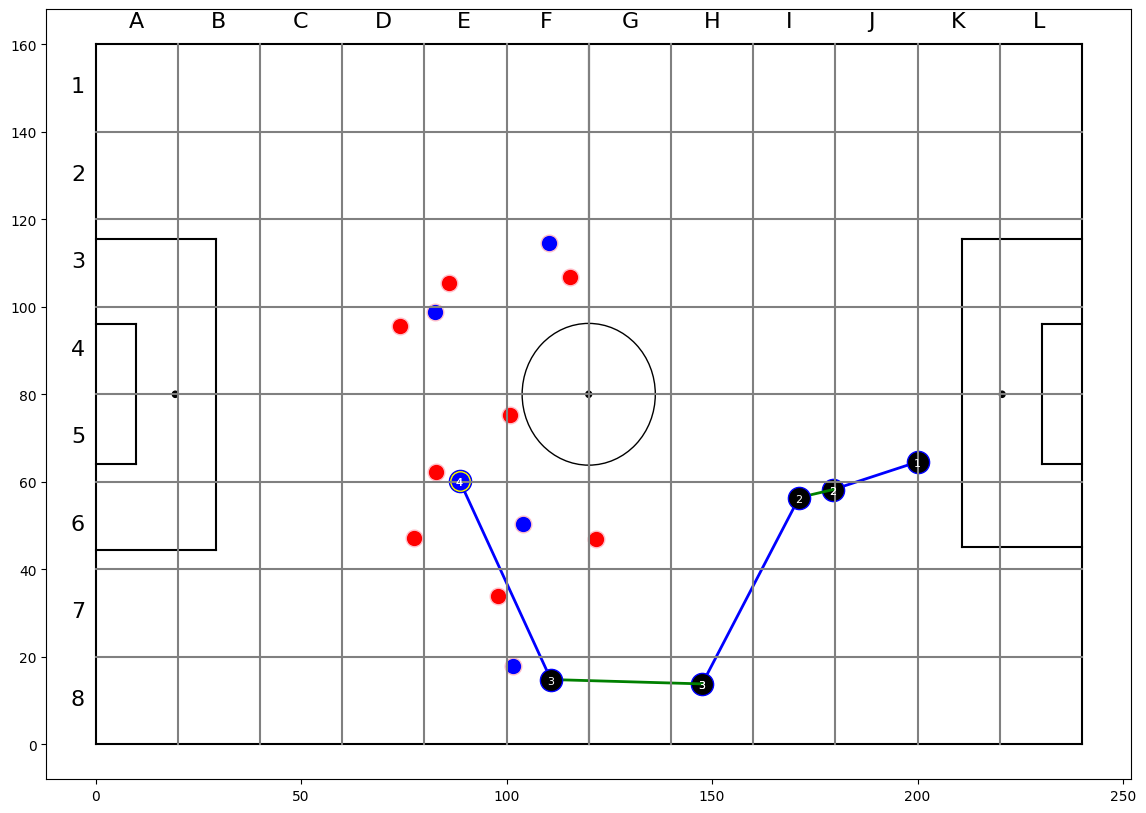

sequence 5
Team: Lech Poznan
1: Radosław Murawski (Pass) <00:47:33.727>
2: Jesper Karlström (Ball Receipt*) <00:47:35.127>
2: Jesper Karlström (Carry) <00:47:35.127>
2: Jesper Karlström (Pass) <00:47:38.974>
3: Adriel D''Avila Ba Loua (Ball Receipt*) <00:47:41.052>
3: Adriel D''Avila Ba Loua (Carry) <00:47:41.052>
3: Adriel D''Avila Ba Loua (Miscontrol) <00:47:43.117>


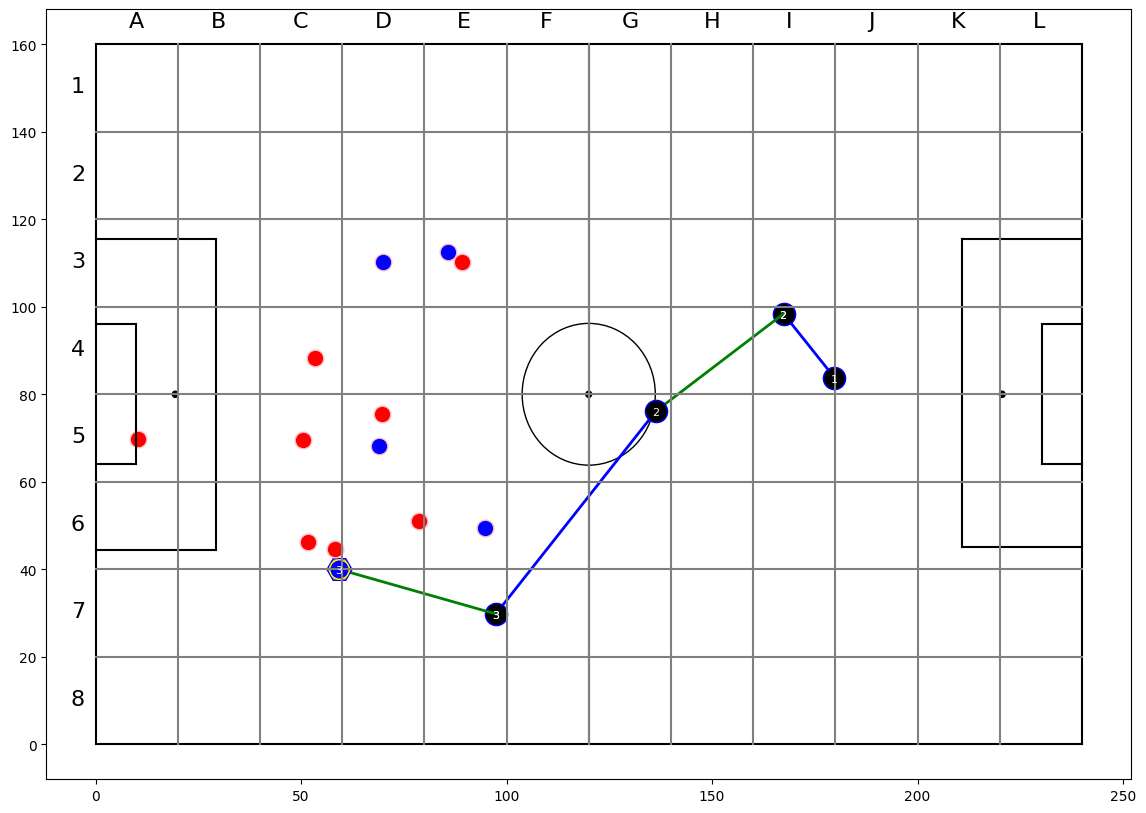

sequence 6
Team: Lech Poznan
1: Ľubomír Šatka (Pass) <00:54:15.656>
2: Filip Bednarek (Ball Receipt*) <00:54:17.750>
2: Filip Bednarek (Carry) <00:54:17.750>
2: Filip Bednarek (Pass) <00:54:17.910>
3: Filip Dagerstål (Ball Receipt*) <00:54:19.039>
3: Filip Dagerstål (Carry) <00:54:19.039>
3: Filip Dagerstål (Pass) <00:54:20.586>
4: Joel Vieira Pereira (Ball Receipt*) <00:54:22.580>
4: Joel Vieira Pereira (Carry) <00:54:22.580>
4: Joel Vieira Pereira (Pass) <00:54:22.620>
5: Adriel D''Avila Ba Loua (Ball Receipt*) <00:54:22.965>


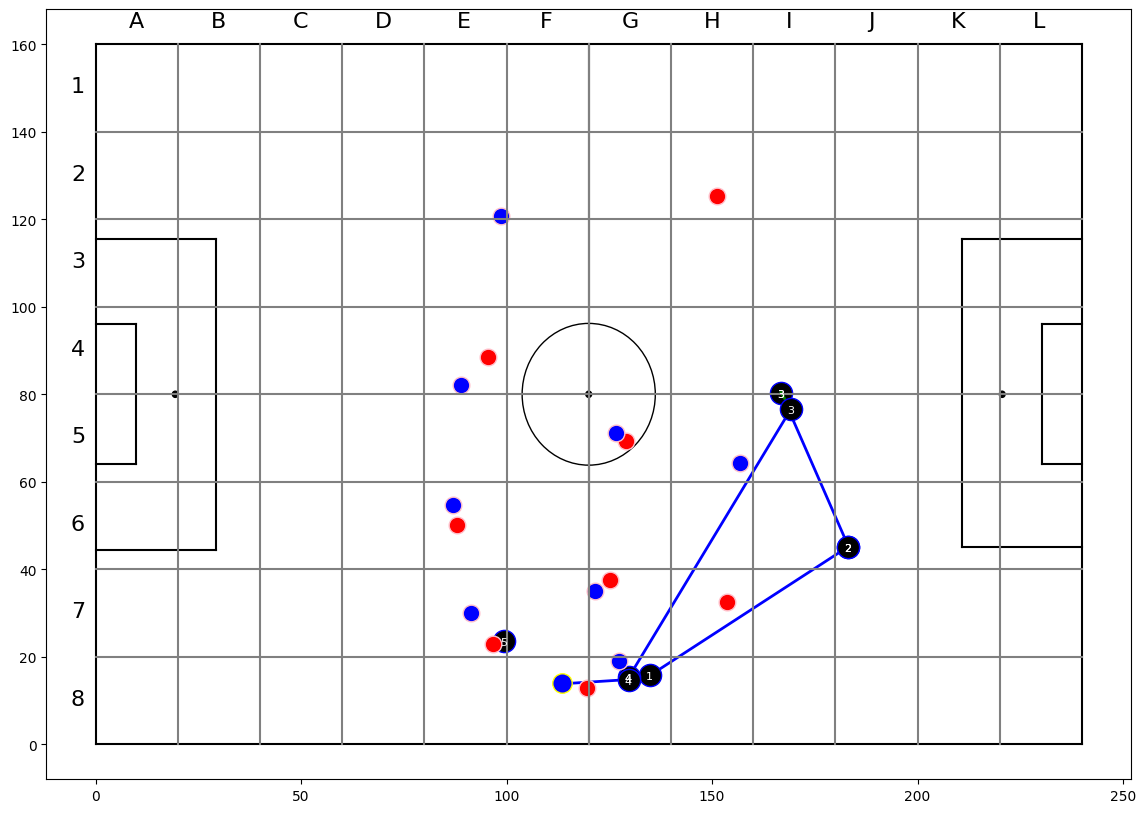

In [7]:
from draw.draw_sequences import draw_events_sequence
from sequences.find_fast_actions import find_fast_actions

fast_attact_lech_2 = find_fast_actions(sequences=sequences, team='Lech Poznan', start_team=start_team, half=2)

for i, s in enumerate(fast_attact_lech_2):
    print(f'sequence {i}')
    draw_events_sequence(s, start_team, 12, 8, scale=2)

sequence 0
Team: Jagiellonia Białystok
1: Marc Gual Huguet (Pass) <00:00:01.243>
2: Israel Puerto Pineda (Ball Receipt*) <00:00:03.390>
2: Israel Puerto Pineda (Carry) <00:00:03.390>
2: Israel Puerto Pineda (Pass) <00:00:04.953>
3: Marc Gual Huguet (Ball Receipt*) <00:00:06.891>
4: Jesper Karlström (Pass) <00:00:06.891>
5: Tomáš Přikryl (Pass) <00:00:08.132>
6: Wojciech Łaski (Ball Receipt*) <00:00:09.835>
6: Wojciech Łaski (Pass) <00:00:09.835>
7: Miłosz Matysik (Ball Receipt*) <00:00:11.472>
8: Mikael Ishak (Pass) <00:00:11.472>
9: Michał Skóraś (Ball Receipt*) <00:00:13.265>


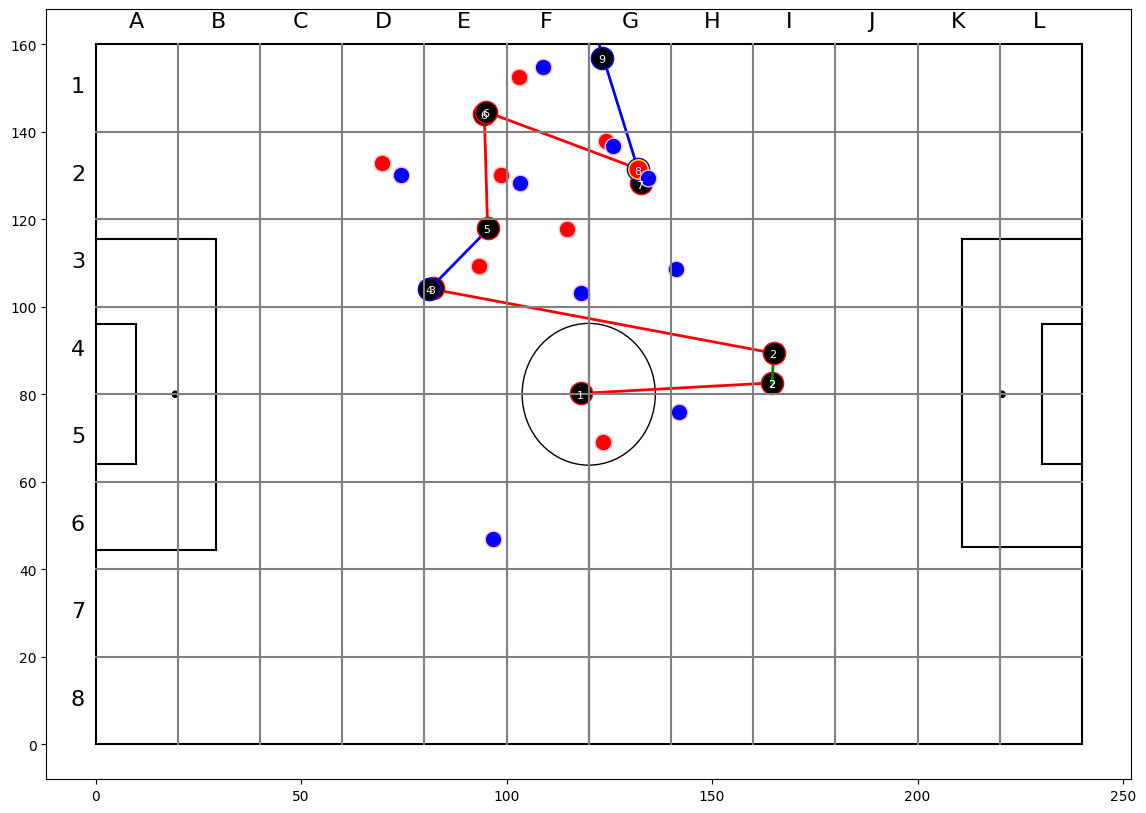

sequence 1
Team: Jagiellonia Białystok
1: Wojciech Łaski (Pass) <00:00:37.422>
2: Marc Gual Huguet (Ball Receipt*) <00:00:38.564>
2: Marc Gual Huguet (Carry) <00:00:38.564>
2: Marc Gual Huguet (Pass) <00:00:38.606>
3: Mateusz Skrzypczak (Ball Receipt*) <00:00:40.854>
3: Mateusz Skrzypczak (Carry) <00:00:40.854>
3: Mateusz Skrzypczak (Pass) <00:00:41.859>
4: Israel Puerto Pineda (Ball Receipt*) <00:00:44.040>
4: Israel Puerto Pineda (Carry) <00:00:44.040>
4: Israel Puerto Pineda (Pass) <00:00:44.105>
5: Zlatan Alomerović (Ball Receipt*) <00:00:46.718>
5: Zlatan Alomerović (Carry) <00:00:46.718>
5: Zlatan Alomerović (Pass) <00:00:48.980>
6: Bojan Nastić (Ball Receipt*) <00:00:51.738>


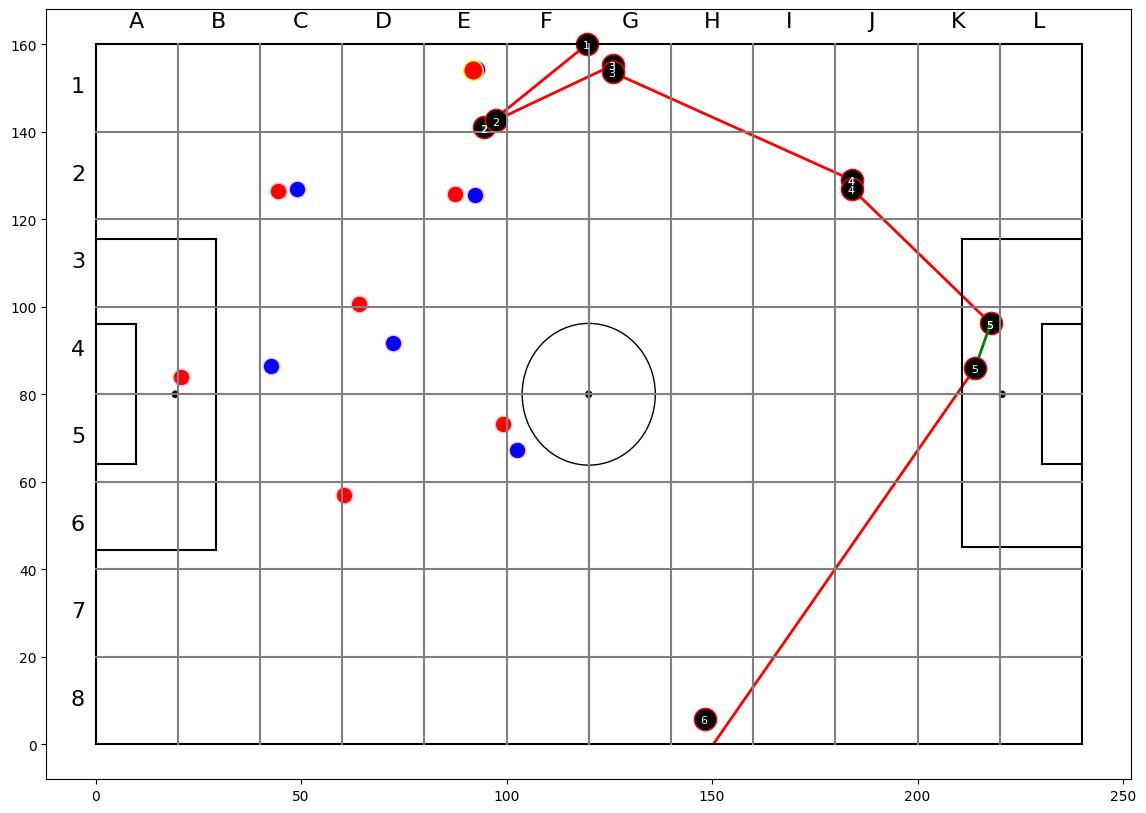

In [8]:
from draw.draw_sequences import draw_events_sequence
from sequences.find_fast_actions import find_fast_actions

fast_attact_jagiellonia_2 = find_fast_actions(sequences=sequences, team='Jagiellonia Białystok', start_team=start_team, half=2)

for i, s in enumerate(fast_attact_jagiellonia_2):
    print(f'sequence {i}')
    draw_events_sequence(s, start_team, 12, 8, scale=2)